<a href="https://colab.research.google.com/github/NethsanduKumarasinghe/EN3160_Assignment_03/blob/main/EN3160_Assignment_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# EN3160 Assignment 3 - Neural Networks

### <span style="font-size: 22px; font-weight: bold;">Index Number: 230355X</span>

### <span style="font-size: 22px; font-weight: bold;">Name: Kumarasinghe M. N.</span>



####GitHub Repository


**Repository:** [EN3160 Assignment 03](https://github.com/NethsanduKumarasinghe/EN3160_Assignment_03)

## Question 1

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [17]:


# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

100%|██████████| 170M/170M [43:44<00:00, 65.0kB/s]


In [35]:
# 2. Define Network Parameters

Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
H = 100             # Number of hidden neurons
K = 10              # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)

w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 1e-2 #(increased since else there is no any improvement in loss while learning)
lr_decay = 0.9
reg = 0
loss_history = []

In [36]:
# 3. Training Loop

for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        z1 = x_train.mm(w1) + b1
        h = torch.sigmoid(z1)
        y_pred = h.mm(w2) + b2

        # Loss calculation
        loss = nn.functional.cross_entropy(y_pred, labels)
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = torch.softmax(y_pred, dim=1)
        dy_pred[torch.arange(Ntr), labels] -= 1
        dy_pred /= Ntr

        dw2 = h.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)

        dh = dy_pred.mm(w2.t())
        dz1 = dh * h * (1 - h)

        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        with torch.no_grad():
            w1 -= lr * dw1
            b1 -= lr * db1
            w2 -= lr * dw2
            b2 -= lr * db2

    if t % 1 == 0:
        print(
            f"Epoch {t + 1}/{iterations}, "
            f"Loss: {running_loss / len(trainloader):.4f}"
        )

    # Learning rate decay
    lr *= lr_decay

Epoch 1/10, Loss: 2.3039
Epoch 2/10, Loss: 2.2902
Epoch 3/10, Loss: 2.1506
Epoch 4/10, Loss: 2.0781
Epoch 5/10, Loss: 2.0447
Epoch 6/10, Loss: 2.0054
Epoch 7/10, Loss: 1.9732
Epoch 8/10, Loss: 1.9499
Epoch 9/10, Loss: 1.9325
Epoch 10/10, Loss: 1.9193


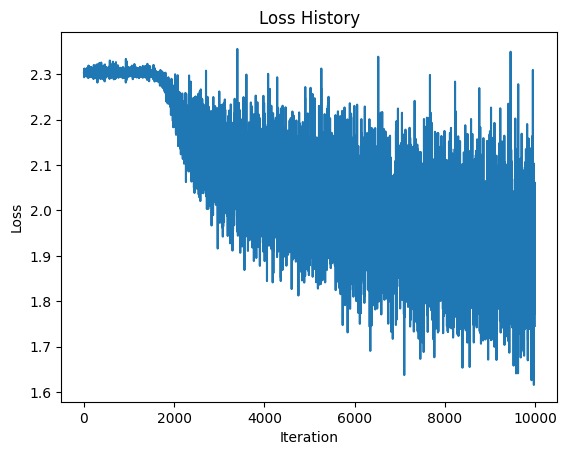

In [37]:
# 4. Plotting the Loss History

plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

In [38]:
# 5. Calculate Accuracy on Training Set

correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        z1 = x_train.mm(w1) + b1
        h = torch.sigmoid(z1)
        y_train_pred = h.mm(w2) + b2

        predicted_train = torch.argmax(y_train_pred, dim=1)

        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train

print(f"Training accuracy: {train_acc:.2f}%")

Training accuracy: 30.22%


In [39]:
# 6. Calculate Accuracy on Test Set

correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        z1 = x_test.mm(w1) + b1
        h = torch.sigmoid(z1)
        y_test_pred = h.mm(w2) + b2

        predicted_test = torch.argmax(y_test_pred, dim=1)

        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test

print(f"Test accuracy: {test_acc:.2f}%")

Test accuracy: 30.65%


### Results and Discussion

The network was trained for 10 epochs using a hidden layer containing
100 sigmoid neurons and cross-entropy loss.

The initial experiment produced the following results:

- Training accuracy: 30.22%
- Test accuracy: 30.65%

The training loss decreased from 2.3039 in the first epoch to 1.9193
in the tenth epoch, indicating that the network learned from the training
data.

The test accuracy was slightly higher than the training accuracy. This
difference is small and does not, by itself, indicate a problem with the
model.

The network's performance is limited by its relatively simple architecture
and the short training duration. The experiment demonstrates how a hidden
layer, cross-entropy loss, and manual backpropagation can be used to train
a dense neural network for multi-class image classification.

## Question 2
2(a).

In [40]:
# 1. Dataloading

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

batch_size = 64

trainset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

testset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.92MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 127kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.18MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.67MB/s]


In [41]:
# 2. Define LeNet-5
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()

        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)

        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(torch.tanh(self.conv1(x)))
        x = self.pool(torch.tanh(self.conv2(x)))

        x = x.view(x.size(0), -1)

        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        x = self.fc3(x)

        return x

In [42]:
model_lenet = LeNet5().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_lenet.parameters(), lr=0.001)

epochs = 10

In [43]:
# 3. Training Loop

train_losses_lenet = []
test_losses_lenet = []
train_accs_lenet = []
test_accs_lenet = []

for epoch in range(epochs):
    model_lenet.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model_lenet(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        predicted = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    model_lenet.eval()
    test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model_lenet(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            predicted = outputs.argmax(dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_loss /= total
    test_acc = 100 * correct / total

    train_losses_lenet.append(train_loss)
    test_losses_lenet.append(test_loss)
    train_accs_lenet.append(train_acc)
    test_accs_lenet.append(test_acc)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}%"
    )

Epoch 1/10 | Train Loss: 0.2506 | Train Acc: 93.08% | Test Loss: 0.0806 | Test Acc: 97.40%
Epoch 2/10 | Train Loss: 0.0734 | Train Acc: 97.72% | Test Loss: 0.0494 | Test Acc: 98.56%
Epoch 3/10 | Train Loss: 0.0517 | Train Acc: 98.42% | Test Loss: 0.0504 | Test Acc: 98.30%
Epoch 4/10 | Train Loss: 0.0412 | Train Acc: 98.69% | Test Loss: 0.0474 | Test Acc: 98.53%
Epoch 5/10 | Train Loss: 0.0338 | Train Acc: 98.90% | Test Loss: 0.0408 | Test Acc: 98.71%
Epoch 6/10 | Train Loss: 0.0275 | Train Acc: 99.13% | Test Loss: 0.0493 | Test Acc: 98.40%
Epoch 7/10 | Train Loss: 0.0240 | Train Acc: 99.22% | Test Loss: 0.0382 | Test Acc: 98.81%
Epoch 8/10 | Train Loss: 0.0202 | Train Acc: 99.39% | Test Loss: 0.0376 | Test Acc: 98.78%
Epoch 9/10 | Train Loss: 0.0182 | Train Acc: 99.39% | Test Loss: 0.0409 | Test Acc: 98.76%
Epoch 10/10 | Train Loss: 0.0158 | Train Acc: 99.48% | Test Loss: 0.0428 | Test Acc: 98.71%


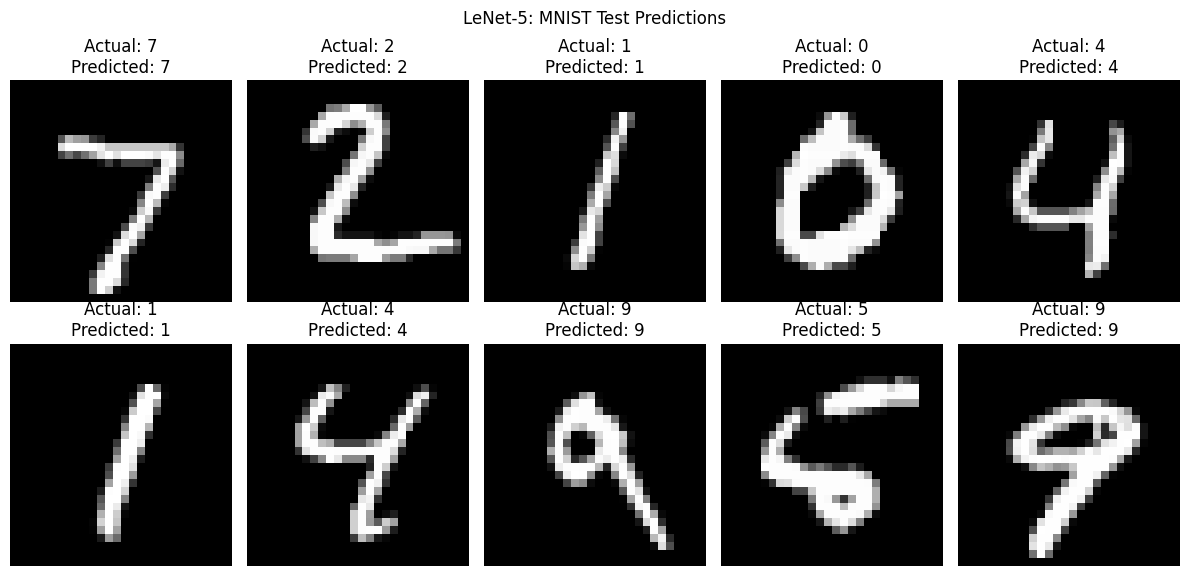

In [48]:
# Display sample predictions from the test set

model_lenet.eval()
inputs, labels = next(iter(testloader))
inputs_device = inputs.to(device)

with torch.no_grad():
    outputs = model_lenet(inputs_device)
    predictions = outputs.argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image = inputs[i].squeeze().numpy()
    actual = labels[i].item()
    predicted = predictions[i].item()

    ax.imshow(image, cmap='gray')
    ax.set_title(f"Actual: {actual}\nPredicted: {predicted}")
    ax.axis('off')

plt.suptitle("LeNet-5: MNIST Test Predictions")
plt.tight_layout()
plt.show()

In [47]:
print(f"LeNet-5 Training Accuracy: {train_accs_lenet[-1]:.2f}%")
print(f"LeNet-5 Test Accuracy: {test_accs_lenet[-1]:.2f}%")

LeNet-5 Training Accuracy: 99.48%
LeNet-5 Test Accuracy: 98.71%


2(b) .

In [49]:
# 1. Define Modern CNN

class ModernCNN(nn.Module):
    def __init__(self):
        super(ModernCNN, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.5)

        self.fc1 = nn.Linear(128 * 3 * 3, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))

        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

In [50]:
model_cnn = ModernCNN().to(device)

criterion_cnn = nn.CrossEntropyLoss()
optimizer_cnn = optim.Adam(model_cnn.parameters(), lr=0.001)

epochs = 10

In [51]:
# 2. Training Loop

import torch.nn.functional as F

train_losses_cnn = []
test_losses_cnn = []
train_accs_cnn = []
test_accs_cnn = []

for epoch in range(epochs):
    model_cnn.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer_cnn.zero_grad()

        outputs = model_cnn(inputs)
        loss = criterion_cnn(outputs, labels)

        loss.backward()
        optimizer_cnn.step()

        running_loss += loss.item() * inputs.size(0)
        predicted = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    model_cnn.eval()
    test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model_cnn(inputs)
            loss = criterion_cnn(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            predicted = outputs.argmax(dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_loss /= total
    test_acc = 100 * correct / total

    train_losses_cnn.append(train_loss)
    test_losses_cnn.append(test_loss)
    train_accs_cnn.append(train_acc)
    test_accs_cnn.append(test_acc)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}%"
    )

Epoch 1/10 | Train Loss: 0.1822 | Train Acc: 94.64% | Test Loss: 0.0394 | Test Acc: 98.59%
Epoch 2/10 | Train Loss: 0.0715 | Train Acc: 97.91% | Test Loss: 0.0324 | Test Acc: 98.90%
Epoch 3/10 | Train Loss: 0.0547 | Train Acc: 98.39% | Test Loss: 0.0289 | Test Acc: 99.06%
Epoch 4/10 | Train Loss: 0.0445 | Train Acc: 98.70% | Test Loss: 0.0246 | Test Acc: 99.20%
Epoch 5/10 | Train Loss: 0.0372 | Train Acc: 98.90% | Test Loss: 0.0255 | Test Acc: 99.23%
Epoch 6/10 | Train Loss: 0.0316 | Train Acc: 99.08% | Test Loss: 0.0252 | Test Acc: 99.19%
Epoch 7/10 | Train Loss: 0.0281 | Train Acc: 99.12% | Test Loss: 0.0250 | Test Acc: 99.29%
Epoch 8/10 | Train Loss: 0.0235 | Train Acc: 99.27% | Test Loss: 0.0277 | Test Acc: 99.28%
Epoch 9/10 | Train Loss: 0.0226 | Train Acc: 99.31% | Test Loss: 0.0236 | Test Acc: 99.30%
Epoch 10/10 | Train Loss: 0.0216 | Train Acc: 99.34% | Test Loss: 0.0213 | Test Acc: 99.36%


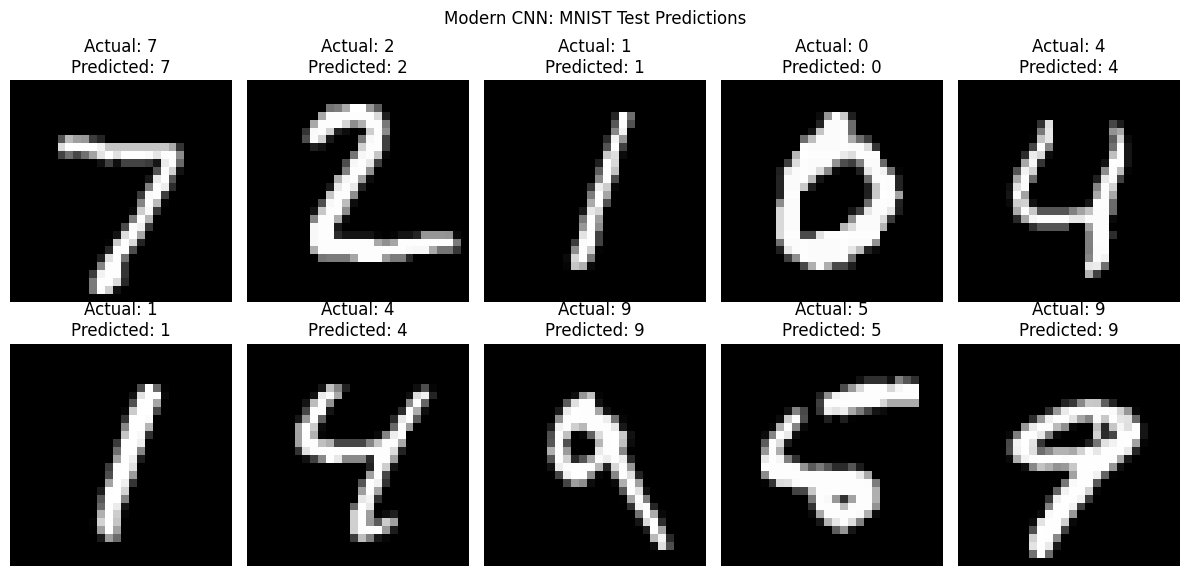

In [57]:
# Display sample predictions from the test set

model_cnn.eval()

inputs, labels = next(iter(testloader))
inputs_device = inputs.to(device)

with torch.no_grad():
    outputs = model_cnn(inputs_device)
    predictions = outputs.argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image = inputs[i].squeeze().numpy()
    actual = labels[i].item()
    predicted = predictions[i].item()

    ax.imshow(image, cmap='gray')
    ax.set_title(f"Actual: {actual}\nPredicted: {predicted}")
    ax.axis('off')

plt.suptitle("Modern CNN: MNIST Test Predictions")
plt.tight_layout()
plt.show()

In [58]:
print(f"Modern CNN Training Accuracy: {train_accs_cnn[-1]:.2f}%")
print(f"Modern CNN Test Accuracy: {test_accs_cnn[-1]:.2f}%")

Modern CNN Training Accuracy: 99.34%
Modern CNN Test Accuracy: 99.36%


2(c).

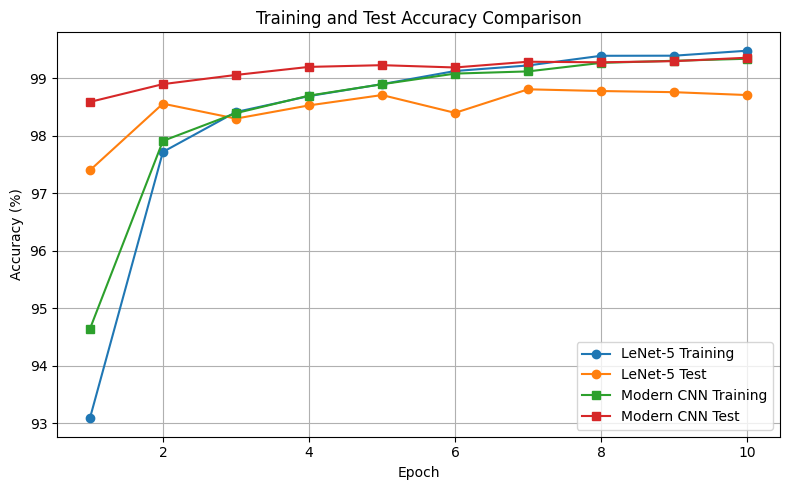

In [52]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, epochs + 1), train_accs_lenet, marker='o', label='LeNet-5 Training')
plt.plot(range(1, epochs + 1), test_accs_lenet, marker='o', label='LeNet-5 Test')
plt.plot(range(1, epochs + 1), train_accs_cnn, marker='s', label='Modern CNN Training')
plt.plot(range(1, epochs + 1), test_accs_cnn, marker='s', label='Modern CNN Test')

plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Training and Test Accuracy Comparison')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

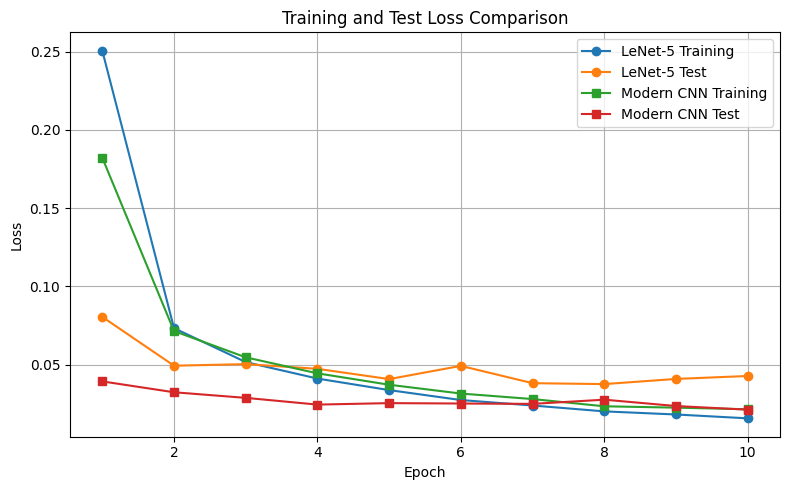

In [53]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, epochs + 1), train_losses_lenet, marker='o', label='LeNet-5 Training')
plt.plot(range(1, epochs + 1), test_losses_lenet, marker='o', label='LeNet-5 Test')
plt.plot(range(1, epochs + 1), train_losses_cnn, marker='s', label='Modern CNN Training')
plt.plot(range(1, epochs + 1), test_losses_cnn, marker='s', label='Modern CNN Test')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Test Loss Comparison')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

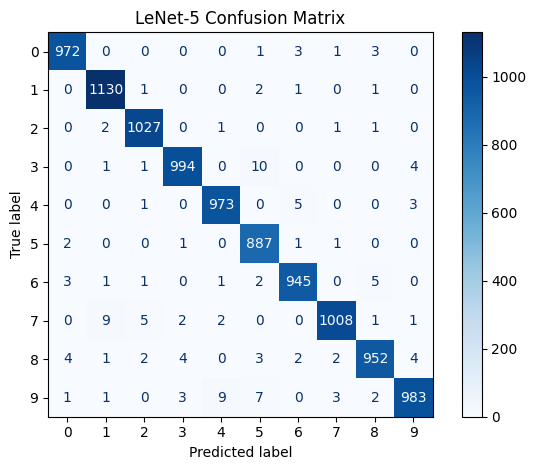

In [54]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model_lenet.eval()
y_true_lenet = []
y_pred_lenet = []

with torch.no_grad():
    for inputs, labels in testloader:
        inputs = inputs.to(device)
        outputs = model_lenet(inputs)

        y_true_lenet.extend(labels.numpy())
        y_pred_lenet.extend(outputs.argmax(dim=1).cpu().numpy())

cm_lenet = confusion_matrix(y_true_lenet, y_pred_lenet)

ConfusionMatrixDisplay(
    confusion_matrix=cm_lenet,
    display_labels=range(10)
).plot(cmap='Blues', values_format='d')

plt.title('LeNet-5 Confusion Matrix')
plt.tight_layout()
plt.show()

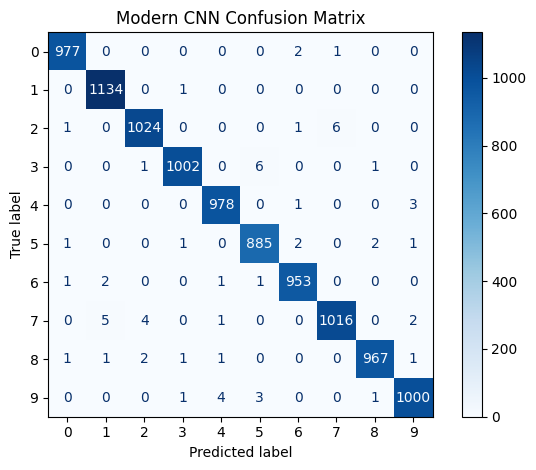

In [55]:
model_cnn.eval()
y_true_cnn = []
y_pred_cnn = []

with torch.no_grad():
    for inputs, labels in testloader:
        inputs = inputs.to(device)
        outputs = model_cnn(inputs)

        y_true_cnn.extend(labels.numpy())
        y_pred_cnn.extend(outputs.argmax(dim=1).cpu().numpy())

cm_cnn = confusion_matrix(y_true_cnn, y_pred_cnn)

ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=range(10)
).plot(cmap='Blues', values_format='d')

plt.title('Modern CNN Confusion Matrix')
plt.tight_layout()
plt.show()

In [56]:
print(f"LeNet-5 Training Accuracy: {train_accs_lenet[-1]:.2f}%")
print(f"LeNet-5 Test Accuracy: {test_accs_lenet[-1]:.2f}%")
print(f"Modern CNN Training Accuracy: {train_accs_cnn[-1]:.2f}%")
print(f"Modern CNN Test Accuracy: {test_accs_cnn[-1]:.2f}%")

LeNet-5 Training Accuracy: 99.48%
LeNet-5 Test Accuracy: 98.71%
Modern CNN Training Accuracy: 99.34%
Modern CNN Test Accuracy: 99.36%


### Results and Discussion

| Model | Training Accuracy | Test Accuracy |
|---|---:|---:|
| LeNet-5 | 99.48% | 98.71% |
| Modern CNN | 99.34% | 99.36% |

- **Higher test accuracy:** The Modern CNN achieved 99.36%, outperforming
  LeNet-5 by 0.65 percentage points.
- **Training performance:** LeNet-5 achieved a slightly higher training
  accuracy, while the Modern CNN performed better on the test set.
- **Generalization:** The Modern CNN's results suggest better generalization
  in this experiment. Its batch normalization and dropout may help, although
  this single comparison cannot establish that they caused the improvement.

Overall, both models achieved high accuracy after 10 epochs, with the
Modern CNN obtaining the higher test accuracy.

## Question 3

In [59]:
import copy
import time
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

In [60]:
!wget -q https://download.pytorch.org/tutorial/hymenoptera_data.zip
!unzip -qo hymenoptera_data.zip

In [61]:
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])
}

data_dir = 'hymenoptera_data'

image_datasets = {
    x: ImageFolder(
        f'{data_dir}/{x}',
        data_transforms[x]
    )
    for x in ['train', 'val']
}

dataloaders = {
    x: DataLoader(
        image_datasets[x],
        batch_size=32,
        shuffle=(x == 'train'),
        num_workers=2
    )
    for x in ['train', 'val']
}

dataset_sizes = {
    x: len(image_datasets[x])
    for x in ['train', 'val']
}

class_names = image_datasets['train'].classes

print(class_names)
print(dataset_sizes)

['ants', 'bees']
{'train': 244, 'val': 153}


In [62]:
def train_model(model, criterion, optimizer, num_epochs=10):
    since = time.time()

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    history = {
        'train_loss': [],
        'val_loss': [],
        'train_acc': [],
        'val_acc': []
    }

    for epoch in range(num_epochs):
        print(f'Epoch {epoch + 1}/{num_epochs}')

        for phase in ['train', 'val']:
            model.train() if phase == 'train' else model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    preds = outputs.argmax(dim=1)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += (preds == labels).sum().item()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects / dataset_sizes[phase]

            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc)

            print(
                f'{phase} Loss: {epoch_loss:.4f} '
                f'Acc: {epoch_acc:.4f}'
            )

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_model_wts)

    print(f'Training time: {(time.time() - since):.1f}s')
    print(f'Best validation accuracy: {best_acc:.4f}')

    return model, history

3(a).

In [63]:

weights = models.ResNet18_Weights.DEFAULT
model_ft = models.resnet18(weights=weights)

num_ftrs = model_ft.fc.in_features
model_ft.fc = nn.Linear(num_ftrs, 2)

model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_ft = optim.SGD(
    model_ft.parameters(),
    lr=0.001,
    momentum=0.9
)

cuda


In [64]:
model_ft, history_ft = train_model(
    model_ft,
    criterion,
    optimizer_ft,
    num_epochs=10
)

Epoch 1/10
train Loss: 0.6846 Acc: 0.5574
val Loss: 0.5088 Acc: 0.7516
Epoch 2/10
train Loss: 0.4411 Acc: 0.8115
val Loss: 0.3104 Acc: 0.9216
Epoch 3/10
train Loss: 0.3446 Acc: 0.8689
val Loss: 0.2414 Acc: 0.9281
Epoch 4/10
train Loss: 0.2512 Acc: 0.9057
val Loss: 0.2103 Acc: 0.9346
Epoch 5/10
train Loss: 0.1940 Acc: 0.9385
val Loss: 0.1924 Acc: 0.9477
Epoch 6/10
train Loss: 0.1796 Acc: 0.9385
val Loss: 0.1734 Acc: 0.9477
Epoch 7/10
train Loss: 0.1752 Acc: 0.9344
val Loss: 0.1728 Acc: 0.9477
Epoch 8/10
train Loss: 0.1855 Acc: 0.9262
val Loss: 0.1683 Acc: 0.9542
Epoch 9/10
train Loss: 0.2415 Acc: 0.8934
val Loss: 0.2096 Acc: 0.9281
Epoch 10/10
train Loss: 0.1593 Acc: 0.9508
val Loss: 0.1634 Acc: 0.9477
Training time: 25.1s
Best validation accuracy: 0.9542


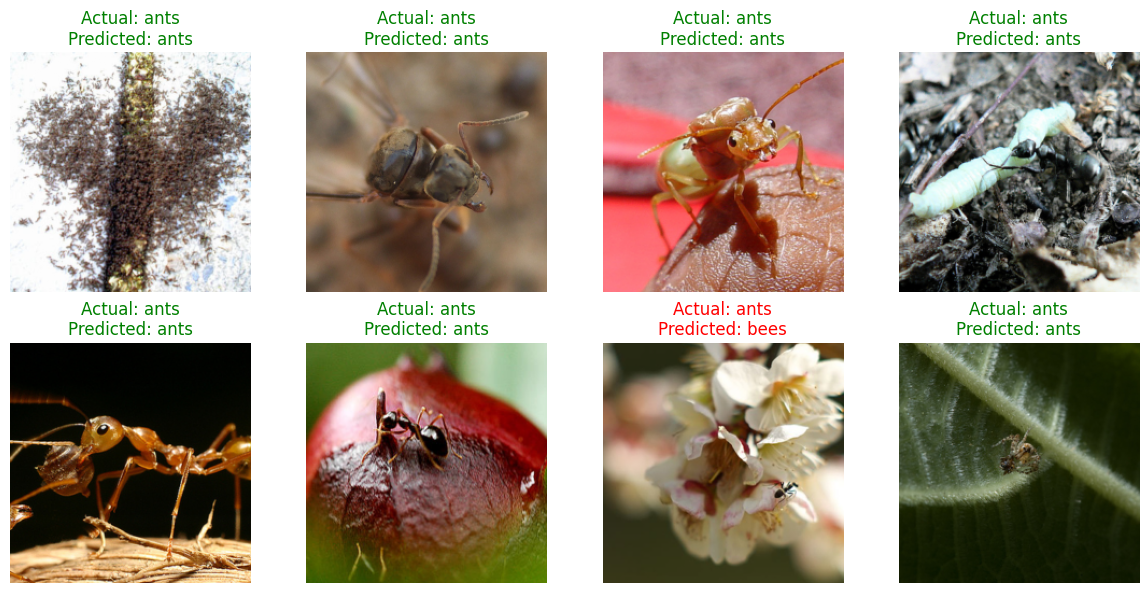

In [65]:
# Visualize Fine-tuning Predictions

model_ft.eval()

inputs, labels = next(iter(dataloaders['val']))
inputs_device = inputs.to(device)

with torch.no_grad():
    outputs = model_ft(inputs_device)
    predictions = outputs.argmax(dim=1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.flatten()

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

for i, ax in enumerate(axes):
    image = inputs[i] * std + mean
    image = image.permute(1, 2, 0).clamp(0, 1)

    actual = class_names[labels[i].item()]
    predicted = class_names[predictions[i].item()]

    ax.imshow(image)
    ax.set_title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color='green' if actual == predicted else 'red'
    )
    ax.axis('off')

plt.tight_layout()
plt.show()

3(b).

In [66]:
model_conv = models.resnet18(weights=weights)

for param in model_conv.parameters():
    param.requires_grad = False

num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)

model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_conv = optim.SGD(
    model_conv.fc.parameters(),
    lr=0.001,
    momentum=0.9
)

In [67]:
model_conv, history_conv = train_model(
    model_conv,
    criterion,
    optimizer_conv,
    num_epochs=10
)

Epoch 1/10
train Loss: 0.7587 Acc: 0.4836
val Loss: 0.5969 Acc: 0.7320
Epoch 2/10
train Loss: 0.5533 Acc: 0.7500
val Loss: 0.4260 Acc: 0.8824
Epoch 3/10
train Loss: 0.3968 Acc: 0.8893
val Loss: 0.2971 Acc: 0.9216
Epoch 4/10
train Loss: 0.3417 Acc: 0.8893
val Loss: 0.2511 Acc: 0.9346
Epoch 5/10
train Loss: 0.2853 Acc: 0.8975
val Loss: 0.2300 Acc: 0.9346
Epoch 6/10
train Loss: 0.2546 Acc: 0.9098
val Loss: 0.2236 Acc: 0.9477
Epoch 7/10
train Loss: 0.2330 Acc: 0.9467
val Loss: 0.2004 Acc: 0.9412
Epoch 8/10
train Loss: 0.2467 Acc: 0.9180
val Loss: 0.1948 Acc: 0.9542
Epoch 9/10
train Loss: 0.2208 Acc: 0.9221
val Loss: 0.1903 Acc: 0.9477
Epoch 10/10
train Loss: 0.2099 Acc: 0.9344
val Loss: 0.1838 Acc: 0.9412
Training time: 24.9s
Best validation accuracy: 0.9542


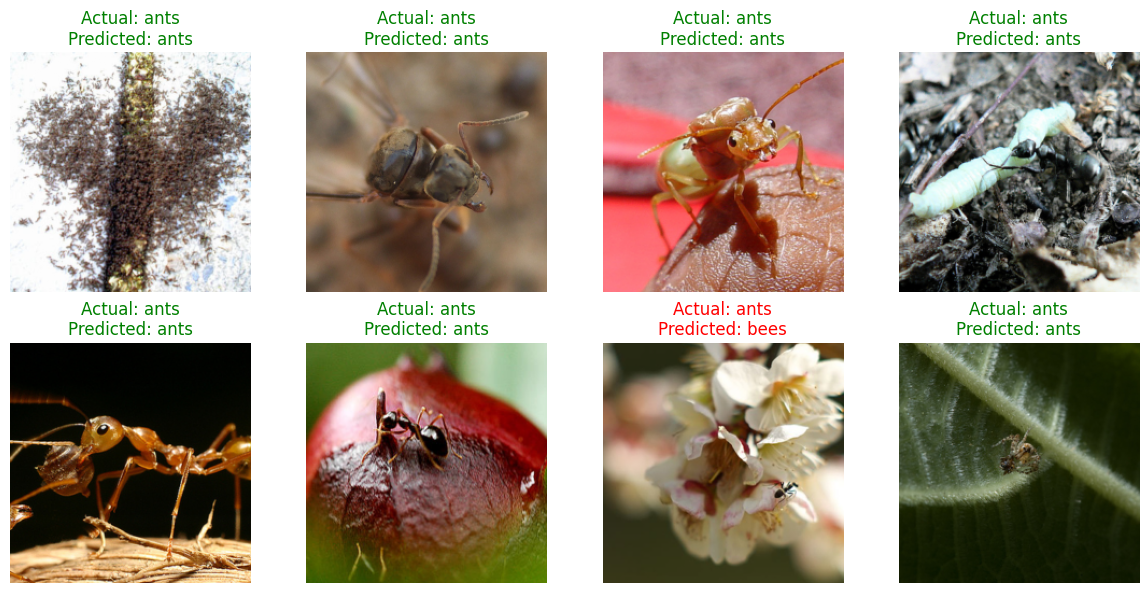

In [68]:
# Visualize Feature Extraction Predictions

model_conv.eval()

inputs, labels = next(iter(dataloaders['val']))
inputs_device = inputs.to(device)

with torch.no_grad():
    outputs = model_conv(inputs_device)
    predictions = outputs.argmax(dim=1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.flatten()

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

for i, ax in enumerate(axes):
    image = inputs[i] * std + mean
    image = image.permute(1, 2, 0).clamp(0, 1)

    actual = class_names[labels[i].item()]
    predicted = class_names[predictions[i].item()]

    ax.imshow(image)
    ax.set_title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color='green' if actual == predicted else 'red'
    )
    ax.axis('off')

plt.tight_layout()
plt.show()

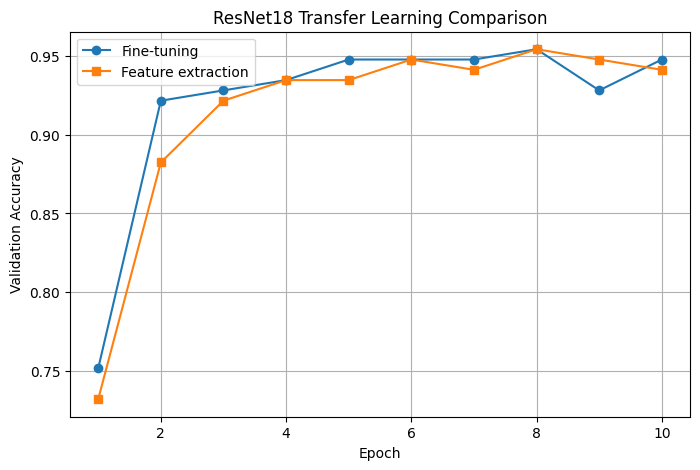

In [69]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    history_ft['val_acc'],
    marker='o',
    label='Fine-tuning'
)

plt.plot(
    range(1, 11),
    history_conv['val_acc'],
    marker='s',
    label='Feature extraction'
)

plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.title('ResNet18 Transfer Learning Comparison')
plt.legend()
plt.grid(True)
plt.show()

In [70]:
print(
    f"Fine-tuning best validation accuracy: "
    f"{max(history_ft['val_acc']) * 100:.2f}%"
)

print(
    f"Feature extraction best validation accuracy: "
    f"{max(history_conv['val_acc']) * 100:.2f}%"
)

Fine-tuning best validation accuracy: 95.42%
Feature extraction best validation accuracy: 95.42%


## Results and Discussion

### Comparison of Transfer Learning Approaches

| Approach | Best Validation Accuracy |
|---|---:|
| Fine-tuning | 95.42% |
| Feature Extraction | 95.42% |

Both fine-tuning and feature extraction achieved a best validation accuracy
of **95.42%** after 10 epochs. Fine-tuning achieved a final validation
accuracy of 94.77%, while feature extraction achieved 94.12%.

Fine-tuning allows all ResNet18 layers to adapt to the target dataset,
whereas feature extraction keeps the pretrained layers frozen and trains
only the final classification layer. Although fine-tuning achieved slightly
higher final validation accuracy, both approaches reached the same best
accuracy in this experiment.

Overall, both transfer learning strategies effectively classified ants and
bees, demonstrating the usefulness of ImageNet-pretrained ResNet18 features
for a small image classification dataset.

## Conclusion

This assignment explored neural networks, convolutional neural networks, and transfer learning using PyTorch. Manual backpropagation and cross-entropy loss were implemented for a dense neural network, while LeNet-5 and a modern CNN were developed for handwritten digit classification. Finally, fine-tuning and feature extraction using pretrained ResNet18 were evaluated on the Hymenoptera dataset.

Overall, these experiments demonstrated the effectiveness of deep learning architectures and transfer learning for image classification.